# 03 Renewable energy transition

**Questions**
1. Which African countries are moving towards renewable electricity, and which sources are driving it?
2. Is renewable adoption associated with lower carbon intensity?
3. Does economic development relate to renewable adoption?

**What I expect going in**
- **H1** Non-hydro renewable (solar and wind) shares of electricity have risen since 2010 in most countries that generate any.
- **H2** Countries with higher renewable electricity shares have lower CO2 intensity of GDP.

**Read before interpreting:** the World Bank's renewable share of *final energy* (B01) counts firewood and charcoal, so it is high where people are poor, not where the energy system is modern. Section 4 shows this. Here the transition is measured with electricity generation (Ember, via OWID) and access to clean cooking. Hydro shares move with rainfall, so drought years (Zambia, Zimbabwe) show up as dips.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
                     "figure.dpi": 110, "font.size": 9})
BLUE, GREY, RED, GREEN = "#1f4e79", "#7f7f7f", "#c00000", "#2f6f4f"

DATA = Path("data")
OUT = Path("outputs") / "03 energy"
OUT.mkdir(parents=True, exist_ok=True)
for f in OUT.glob("*"):
    f.unlink()          # start each run with an empty outputs folder

obs = pd.read_csv(DATA / "observations.csv", dtype={"flag": str})        # long: iso3, year, indicator_id, value, source, flag
panel = pd.read_csv(DATA / "panel.csv")                # wide: one row per country-year
ind = pd.read_csv(DATA / "indicators.csv").set_index("indicator_id")
cty = pd.read_csv(DATA / "countries.csv").set_index("iso3")
AFRICA = cty.index[cty["group"] == "Africa"].tolist()
name = cty["country_name"].to_dict()
af = obs[obs["iso3"].isin(AFRICA)]
afp = panel[panel["iso3"].isin(AFRICA)]


def label(i):
    return f"{ind.at[i, 'indicator_name']} ({ind.at[i, 'unit']})" if i in ind.index else i


def has(*ids):
    missing = [i for i in ids if i not in panel.columns]
    if missing:
        print("Not in the data, skipped:", ", ".join(missing))
    return not missing


def latest(i, frame=None, max_age=5):
    """Latest observed value per country. Values more than max_age years older than the
    newest year for that indicator are dropped so stale points do not enter rankings."""
    s = (frame if frame is not None else af)
    s = s[s["indicator_id"] == i].sort_values("year").groupby("iso3").tail(1)
    s = s[s["year"] >= s["year"].max() - max_age]
    return s.assign(country=s["iso3"].map(name)).sort_values("value", ascending=False)[["iso3", "country", "year", "value"]]


def change(i, base=(2000, 2002)):
    """Change from the 2000 to 2002 average (damps single-year noise) to the latest value.
    Percentage change only where the base is above the 10th percentile, so tiny bases
    do not produce meaningless growth rates."""
    s = af[af["indicator_id"] == i]
    b = s[s["year"].between(*base)].groupby("iso3")["value"].mean().rename("base")
    l = s.sort_values("year").groupby("iso3").tail(1).set_index("iso3")[["year", "value"]].rename(columns={"value": "latest", "year": "latest_year"})
    d = l.join(b, how="inner")
    d["abs_change"] = d["latest"] - d["base"]
    floor = d["base"].abs().quantile(0.10)
    d["pct_change"] = np.where(d["base"].abs() > floor, 100 * d["abs_change"] / d["base"].abs(), np.nan)
    d.insert(0, "country", d.index.map(name))
    return d.sort_values("abs_change", ascending=False)


def median_path(i, iso=None):
    """Africa median by year (only years where at least 10 countries report), or one economy's series."""
    if iso:
        s = obs[(obs["indicator_id"] == i) & (obs["iso3"] == iso)]
        return s.set_index("year")["value"].sort_index()
    s = af[af["indicator_id"] == i].groupby("year")["value"].agg(["median", "count"])
    return s.loc[s["count"] >= 10, "median"]


def barh(df, value, title, xlabel, path, n=15, color=BLUE):
    d = df.head(n).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(d) + 1))
    ax.barh(d["country"], d[value], color=color)
    for y, (v, yr) in enumerate(zip(d[value], d.get("year", d.get("latest_year", [""] * len(d))))):
        ax.text(v, y, f" {v:,.2f} ({yr})" if yr != "" else f" {v:,.2f}", va="center", fontsize=7)
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel); ax.grid(axis="y", visible=False)
    fig.tight_layout(); fig.savefig(OUT / path, dpi=150); plt.show()


def save_excel(path, sheets):
    """Tables to Excel in house style: Tahoma 8, bold headers without fill, frozen header, no gridlines."""
    from openpyxl.styles import Font
    with pd.ExcelWriter(OUT / path, engine="openpyxl") as xl:
        for sheet, frame in sheets.items():
            frame.to_excel(xl, sheet_name=sheet[:31])
        for ws in xl.book.worksheets:
            ws.sheet_view.showGridLines = False
            ws.freeze_panes = "B2"
            for row in ws.iter_rows():
                for c in row:
                    c.font = Font(name="Tahoma", size=8, bold=(c.row == 1))
                    if isinstance(c.value, float):
                        c.number_format = "#,##0.00;(#,##0.00);-"
    return sorted(p.name for p in OUT.iterdir())

## 1. Electricity mix: the average African country, 2000 to 2024

B10C: mean 37.7% in 2000, 36.5% in 2010, 32.1% in 2024 (49 countries)
B10A: mean 0.0% in 2000, 0.1% in 2010, 4.6% in 2024 (49 countries)
B10B: mean 0.2% in 2000, 0.1% in 2010, 2.3% in 2024 (49 countries)
B10D: mean 59.4% in 2000, 60.4% in 2010, 58.3% in 2024 (49 countries)


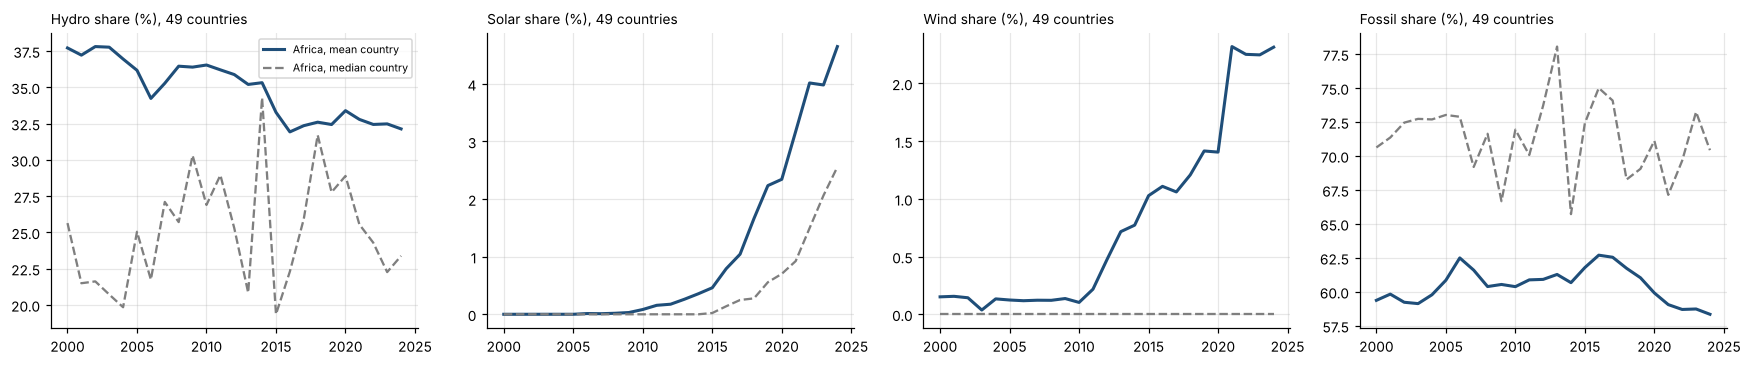

In [2]:
mix_ids = [i for i in ("B10C", "B10A", "B10B", "B10D") if i in panel]
if mix_ids:
    fig, ax = plt.subplots(1, len(mix_ids), figsize=(4 * len(mix_ids), 3.4), sharey=False)
    for a, i in zip(np.atleast_1d(ax), mix_ids):
        # fixed set of countries reporting every year 2000 to 2024, so the line is not moved by countries entering or leaving
        w = afp.pivot_table(index="year", columns="iso3", values=i).loc[2000:2024].dropna(axis=1)
        a.plot(w.index, w.mean(axis=1), color=BLUE, lw=2, label="Africa, mean country")
        a.plot(w.index, w.median(axis=1), "--", color=GREY, label="Africa, median country")
        a.set_title(f"{ind.at[i, 'indicator_name'].replace(' of electricity generation', '')} (%), {w.shape[1]} countries", loc="left", fontsize=9)
        print(f"{i}: mean {w.mean(axis=1).loc[2000]:.1f}% in 2000, {w.mean(axis=1).loc[2010]:.1f}% in 2010, {w.mean(axis=1).loc[2024]:.1f}% in 2024 ({w.shape[1]} countries)")
    np.atleast_1d(ax)[0].legend(fontsize=7)
    fig.tight_layout(); fig.savefig(OUT / "electricity mix trend.png", dpi=150); plt.show()

**The average African grid is still about 58% fossil, and the shift since 2000 has come from solar and wind, not hydro.**

- Across the 49 countries that report every year, the average country's fossil share went from 59.4% (2000) to 58.3% (2024).
- Hydro fell from 37.7% to 32.1%. Solar rose from 0.0% to 4.6% and wind from 0.2% to 2.3%, almost all of it after 2015.

## 2. Solar and wind: who has moved since 2010? (H1)

H1: solar plus wind share rose in 81% of 54 countries; 45 countries now generate some solar or wind


,country,base_2010_12,latest,year,change_pp
iso3,,,,,
NAM,Namibia,0.684,36.586,2024,35.902
DJI,Djibouti,0.000,35.000,2024,35.000
CPV,Cabo Verde,8.843,30.770,2024,21.927
SOM,Somalia,0.000,20.931,2024,20.931
KEN,Kenya,0.302,21.012,2025,20.710
MAR,Morocco,2.825,21.820,2025,18.995
TGO,Togo,0.000,18.310,2024,18.310
SYC,Seychelles,0.000,15.873,2024,15.873
COD,DR Congo,0.000,15.766,2024,15.766


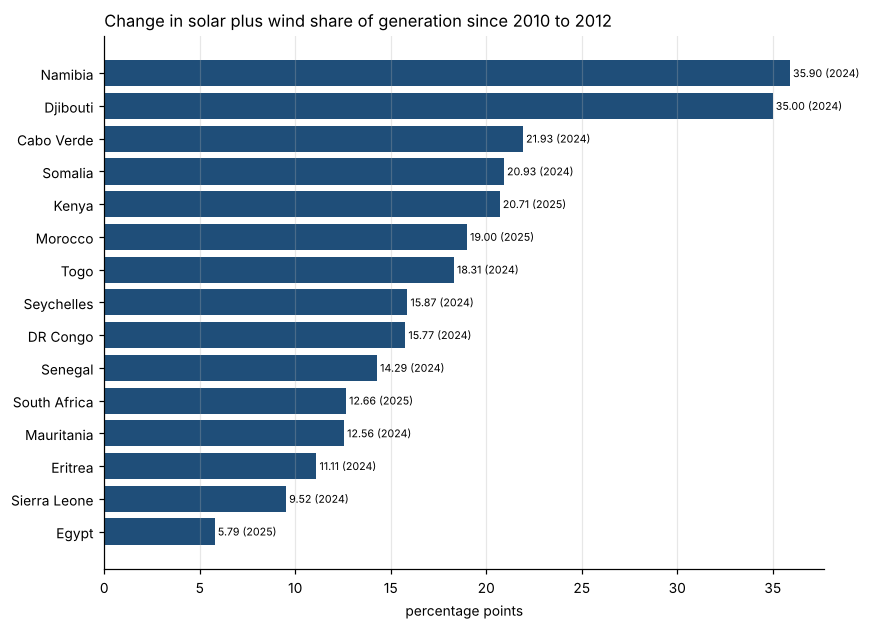

In [3]:
if has("B10A", "B10B"):
    sw = afp.assign(solar_wind=afp["B10A"].fillna(0).where(afp[["B10A", "B10B"]].notna().any(axis=1)) + afp["B10B"].fillna(0))
    base = sw[sw["year"].between(2010, 2012)].groupby("iso3")["solar_wind"].mean()
    last = sw.dropna(subset=["solar_wind"]).sort_values("year").groupby("iso3").tail(1).set_index("iso3")
    t = pd.DataFrame({"base_2010_12": base, "latest": last["solar_wind"], "year": last["year"]}).dropna()
    t.insert(0, "country", t.index.map(name))
    t["change_pp"] = t["latest"] - t["base_2010_12"]
    t = t.sort_values("change_pp", ascending=False)
    print(f"H1: solar plus wind share rose in {(t['change_pp'] > 0).mean():.0%} of {len(t)} countries; "
          f"{(t['latest'] > 0).sum()} countries now generate some solar or wind")
    display(t.head(10))
    barh(t.rename(columns={"change_pp": "value"}), "value", "Change in solar plus wind share of generation since 2010 to 2012", "percentage points", "solar wind change.png")

**H1 supported: the solar plus wind share has risen in 81% of countries since 2010 to 2012, and 45 countries now generate some.**

- Namibia (+35.9 points), Djibouti (+35.0), Cabo Verde (+21.9), Somalia (+20.9), Kenya (+20.7) and Morocco (+19.0) moved the most.

## 3. Hydro dependence and renewable share

,iso3,country,year,value
45433,LSO,Lesotho,2022,100.000
44709,CAF,Central African Republic,2023,100.000
45077,ETH,Ethiopia,2025,100.000
44820,COD,DR Congo,2024,100.000
45644,NAM,Namibia,2024,97.561
46033,UGA,Uganda,2024,97.074
45882,SWZ,Eswatini,2024,96.721
45619,MWI,Malawi,2024,95.628
45795,SLE,Sierra Leone,2024,95.238
45360,KEN,Kenya,2025,90.028


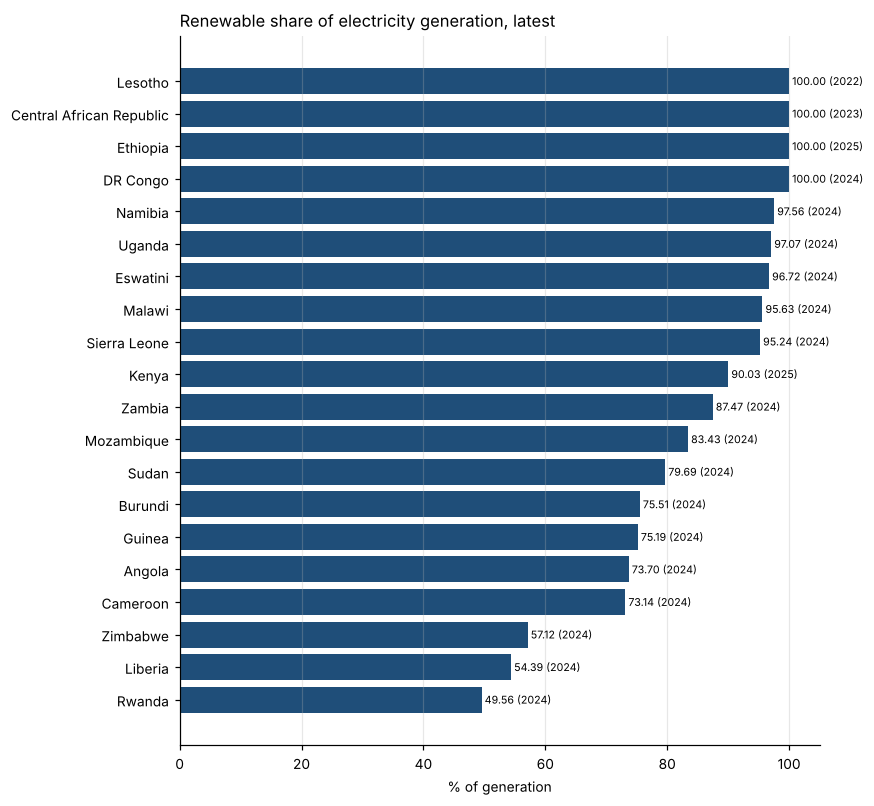

,iso3,country,year,value
42191,LSO,Lesotho,2022,100.000
41467,CAF,Central African Republic,2023,100.000
41835,ETH,Ethiopia,2025,96.464
42377,MWI,Malawi,2024,92.350
42888,ZMB,Zambia,2024,86.207
42791,UGA,Uganda,2024,86.059
42553,SLE,Sierra Leone,2024,85.714
41578,COD,DR Congo,2024,84.171
42302,MOZ,Mozambique,2024,82.365
42503,SDN,Sudan,2024,77.861


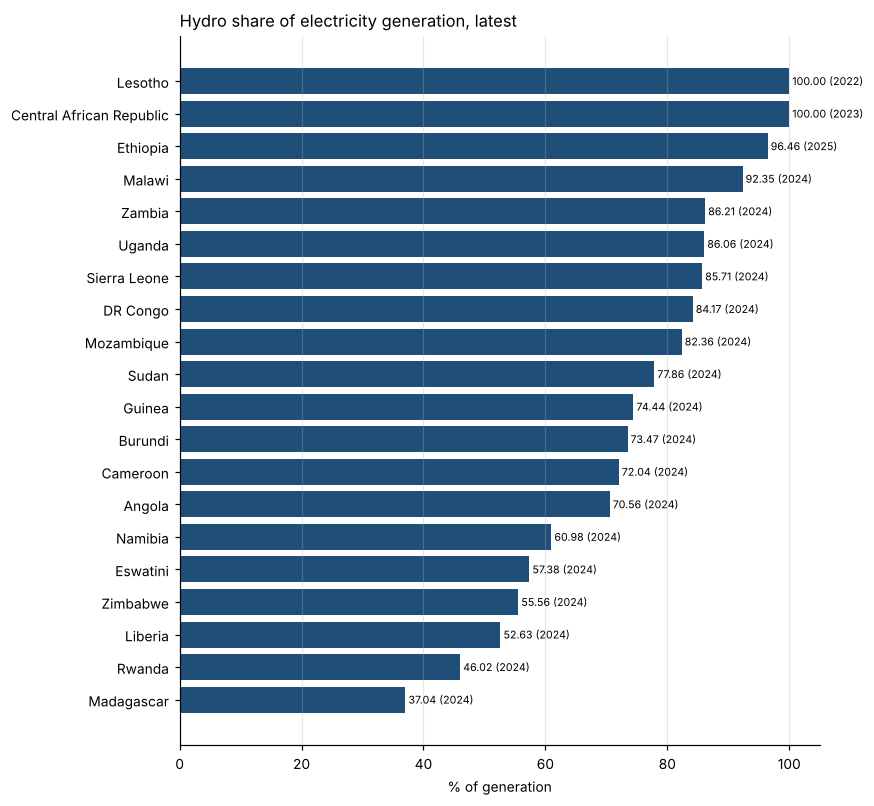

18 countries get half or more of their electricity from hydro: Lesotho, Central African Republic, Ethiopia, Malawi, Zambia, Uganda, Sierra Leone, DR Congo, Mozambique, Sudan, Guinea, Burundi, Cameroon, Angola, Namibia, Eswatini, Zimbabwe, Liberia


In [4]:
for i, title in (("B10E", "Renewable share of electricity generation, latest"), ("B10C", "Hydro share of electricity generation, latest")):
    if i in panel:
        display(latest(i).head(10))
        barh(latest(i), "value", title, "% of generation", f"{i} ranking.png", n=20)
if "B10C" in panel:
    hy = latest("B10C")
    print(f"{(hy['value'] >= 50).sum()} countries get half or more of their electricity from hydro:",
          ", ".join(hy.loc[hy["value"] >= 50, "country"]))

**18 countries get half or more of their electricity from hydro, which leaves them exposed to drought.**

- Lesotho and Central African Republic report 100% hydro, and Ethiopia 96%. Malawi, Zambia, Uganda, Sierra Leone, DR Congo and Mozambique are all above 80%.
- High renewable shares in these countries reflect hydro endowment, not a recent transition.

## 4. Why the final-energy renewable share misleads

Final-energy renewable share vs income: rho = -0.75; vs clean cooking: rho = -0.74; n = 52


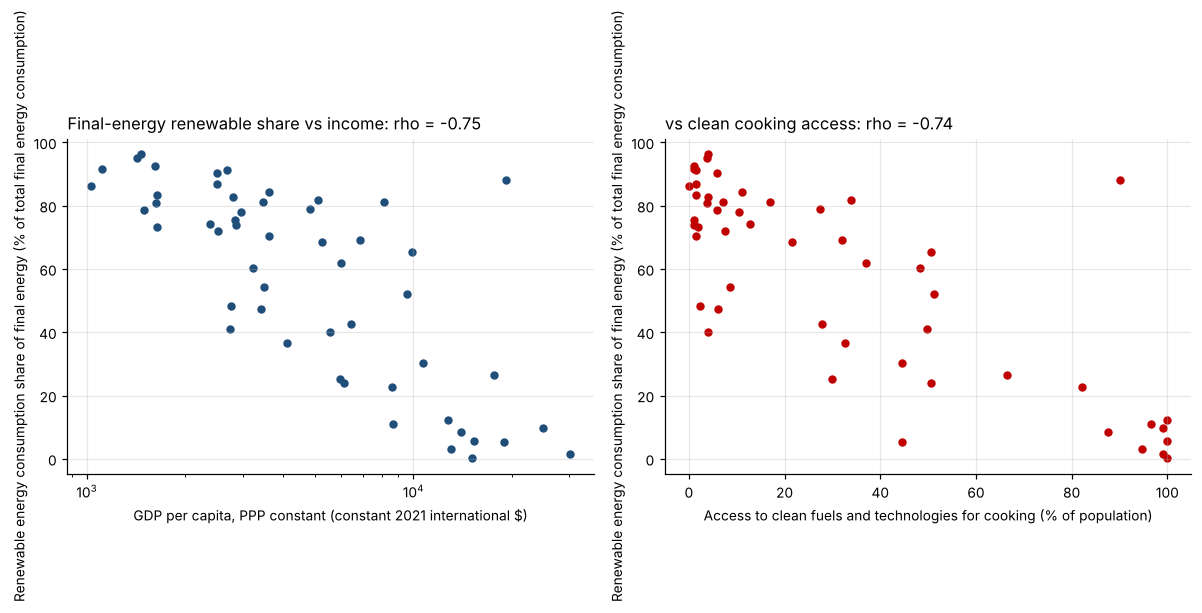

In [5]:
if has("B01", "B08", "G02"):
    s = afp[afp["year"] >= 2015].groupby("iso3")[["B01", "B08", "G02"]].mean().dropna()
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].scatter(s["G02"], s["B01"], color=BLUE, s=20); ax[0].set_xscale("log")
    ax[0].set_xlabel(label("G02")); ax[0].set_ylabel(label("B01"))
    print(f"Final-energy renewable share vs income: rho = {stats.spearmanr(s['G02'], s['B01'])[0]:.2f}; vs clean cooking: rho = {stats.spearmanr(s['B08'], s['B01'])[0]:.2f}; n = {len(s)}")
    ax[0].set_title(f"Final-energy renewable share vs income: rho = {stats.spearmanr(s['G02'], s['B01'])[0]:.2f}", loc="left")
    ax[1].scatter(s["B08"], s["B01"], color=RED, s=20)
    ax[1].set_xlabel(label("B08")); ax[1].set_ylabel(label("B01"))
    ax[1].set_title(f"vs clean cooking access: rho = {stats.spearmanr(s['B08'], s['B01'])[0]:.2f}", loc="left")
    fig.tight_layout(); fig.savefig(OUT / "biomass problem.png", dpi=150); plt.show()

**The final-energy renewable share falls as countries get richer and as clean cooking spreads, so it measures biomass dependence, not transition.**

- Across countries, final-energy renewable share has rho = -0.75 with GDP per capita and rho = -0.74 with access to clean cooking (n = 52).
- This confirms the design choice to measure the transition through electricity generation instead.

## 5. Access to electricity and clean cooking

In [6]:
acc = {i: change(i) for i in ("B06", "B08") if i in panel}
for i, d in acc.items():
    print(f"{label(i)}: median change {d['abs_change'].median():+.1f} points; latest median {d['latest'].median():.1f}")
    display(d.sort_values("latest").head(8))

Access to electricity (% of population): median change +28.6 points; latest median 61.5


,country,latest_year,latest,base,abs_change,pct_change
iso3,,,,,,
TCD,Chad,2024,13.400,3.433,9.967,NaN
MWI,Malawi,2024,15.600,5.200,10.400,NaN
CAF,Central African Republic,2024,18.200,5.933,12.267,206.742
BDI,Burundi,2024,20.100,2.800,17.300,NaN
NER,Niger,2024,21.300,7.900,13.400,169.620
COD,DR Congo,2024,22.500,7.167,15.333,213.953
BFA,Burkina Faso,2024,34.000,9.500,24.500,257.895
MOZ,Mozambique,2024,36.900,6.733,30.167,448.020


Access to clean fuels and technologies for cooking (% of population): median change +6.5 points; latest median 24.5


,country,latest_year,latest,base,abs_change,pct_change
iso3,,,,,,
SSD,South Sudan,2024,0.000,1.000,-1.000,NaN
BDI,Burundi,2024,0.000,0.000,0.000,NaN
CAF,Central African Republic,2024,1.000,1.000,0.000,NaN
LBR,Liberia,2024,1.000,1.000,0.000,NaN
MWI,Malawi,2024,2.000,2.000,0.000,0.000
MDG,Madagascar,2024,2.000,1.000,1.000,NaN
UGA,Uganda,2024,2.000,1.000,1.000,NaN
SLE,Sierra Leone,2024,2.000,0.000,2.000,NaN


**Electricity access has improved strongly, clean cooking has not.**

- Median access to electricity rose by 28.6 points to 61.5%. Chad (13.4%), Malawi (15.6%), Central African Republic, Burundi, Niger and DR Congo remain below 25%.
- Median access to clean cooking rose only 6.5 points, to 24.5%. South Sudan, Burundi, Central African Republic, Liberia, Malawi, Madagascar, Uganda and Sierra Leone are at 2% or below.

## 6. Renewables and carbon intensity (H2, descriptive)

H2 (descriptive): renewable electricity share vs CO2 intensity, Spearman rho = -0.33 (p = 0.018), n = 52


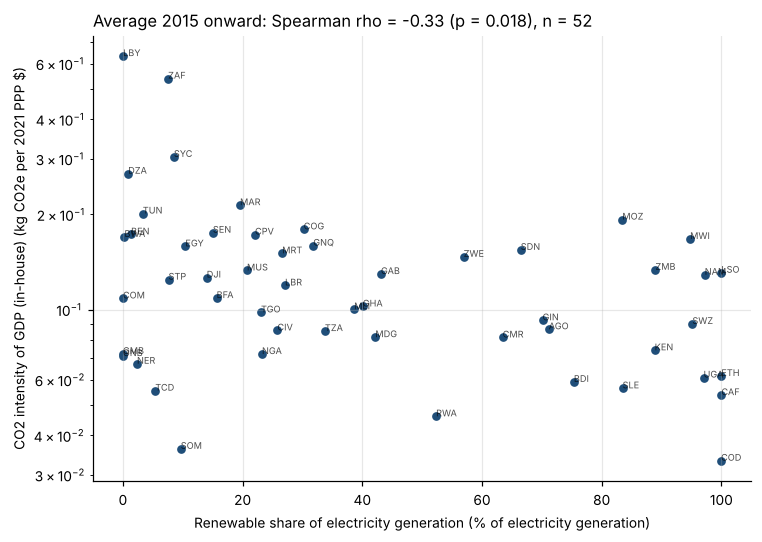

In [7]:
if has("B10E", "X01"):
    s = afp[afp["year"] >= 2015].groupby("iso3")[["B10E", "X01"]].mean().dropna()
    rho, p = stats.spearmanr(s["B10E"], s["X01"])
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(s["B10E"], s["X01"], color=BLUE, s=22)
    for iso, r in s.iterrows():
        ax.annotate(iso, (r["B10E"], r["X01"]), fontsize=6, alpha=0.7)
    print(f"H2 (descriptive): renewable electricity share vs CO2 intensity, Spearman rho = {rho:.2f} (p = {p:.3f}), n = {len(s)}")
    ax.set_yscale("log"); ax.set_xlabel(label("B10E")); ax.set_ylabel(label("X01"))
    ax.set_title(f"Average 2015 onward: Spearman rho = {rho:.2f} (p = {p:.3f}), n = {len(s)}", loc="left")
    fig.tight_layout(); fig.savefig(OUT / "renewables vs intensity.png", dpi=150); plt.show()

**Across countries, a higher renewable electricity share goes with lower CO2 intensity (Spearman rho = -0.33, p = 0.018, n = 52), but within countries over time the panel model finds no significant link (see 08).**

## 7. Save tables

In [8]:
save_excel("energy results.xlsx", {**({"Solar wind change": t} if "t" in globals() else {}),
                                   **{f"{i} latest": latest(i).set_index("iso3") for i in ("B10E", "B10C", "B06", "B08") if i in panel},
                                   **{f"{i} change": d for i, d in acc.items()}})

['B10C ranking.png',
 'B10E ranking.png',
 'biomass problem.png',
 'electricity mix trend.png',
 'energy results.xlsx',
 'renewables vs intensity.png',
 'solar wind change.png']

## What I found

- **Africa's grids are still mostly fossil.** The average country is 58% fossil, almost unchanged since 2000. Hydro has slipped and solar and wind have grown from near zero to about 7% combined.
- **Solar and wind are spreading fast (H1 supported).** The share rose in 81% of countries, led by Namibia, Djibouti, Cabo Verde, Somalia, Kenya and Morocco.
- **Hydro dependence is a climate risk:** 18 countries rely on hydro for at least half their power, including Zambia (86%) and Malawi (92%).
- **Access gaps remain the bigger problem:** electricity access is 61.5% for the median country and clean cooking only 24.5%.
- **The World Bank's renewable energy share is not a transition measure** in Africa. It falls with income (rho = -0.75).

**Why it matters for finance:** in hydro-dependent systems such as Zambia's, a high "renewable share" hides drought risk to power supply and utility earnings. Lenders and investors should treat hydro concentration as a resilience risk. They should treat solar and wind growth, which needs grid and storage capital, as the investment signal.